In [1]:
# S8 - Segment Analysis
# Goal: Compare actual uplift and predicted uplift
# across different groups of users.

from pathlib import Path
import sys
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find our project folder
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from uplift import data as uplift_data

print("Project folder:", ROOT)

# Check the files required for this analysis
files = [
    "data/criteo.parquet",
    "results/feature_selection.csv",
    "results/kept_features.json",
    "results/scores_5m.parquet"
]

for file in files:
    path = ROOT / file
    print(file, "FOUND" if path.exists() else "MISSING")

# Inspect available dataset helper functions
print("\nAvailable data functions:")
print([
    name for name in dir(uplift_data)
    if "split" in name or "take" in name
])

# Inspect our feature selection results
importance = pd.read_csv(ROOT / "results/feature_selection.csv")

print("\nFeature importance:")
print(importance.head())

with open(ROOT / "results/kept_features.json") as f:
    kept = json.load(f)

print("\nKept features:", kept)

Project folder: /Users/kajasaikiran/Desktop/causal-uplift-git
data/criteo.parquet FOUND
results/feature_selection.csv FOUND
results/kept_features.json FOUND
results/scores_5m.parquet FOUND

Available data functions:
['make_splits', 'split_by_row_id', 'take']

Feature importance:
  Unnamed: 0  importance   kept
0         f0      0.0151   True
1         f1      0.0005  False
2         f2      0.1485   True
3         f3      0.0106   True
4         f4      0.0035   True

Kept features: ['f0', 'f2', 'f3', 'f4', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']


In [2]:
# Step 2: Find the 3 most important kept features

import inspect
import pyarrow.parquet as pq

# Give the feature-name column a clearer name
importance = importance.rename(
    columns={"Unnamed: 0": "feature"}
)

# Keep only the features selected by our pipeline
selected = importance[
    importance["feature"].isin(kept)
]

# Select the top 3 based on importance
top_3 = selected.nlargest(3, "importance")

features = top_3["feature"].tolist()

print("Top 3 features:")
print(top_3.to_string(index=False))

# Check how the project's data functions work
print("\nData function inputs:")
print("make_splits:", inspect.signature(uplift_data.make_splits))
print("take:", inspect.signature(uplift_data.take))
print("split_by_row_id:", inspect.signature(uplift_data.split_by_row_id))

# Check the prediction file without loading all rows
scores_info = pq.ParquetFile(
    ROOT / "results/scores_5m.parquet"
)

print("\nPrediction rows:", scores_info.metadata.num_rows)
print("Prediction columns:", scores_info.schema_arrow.names)

Top 3 features:
feature  importance  kept
     f8      0.5682  True
     f9      0.2205  True
     f2      0.1485  True

Data function inputs:
make_splits: (n_rows: int, holdout: int = 2000000, seed: int = 42)
take: (df: pandas.DataFrame, ids: numpy.ndarray) -> pandas.DataFrame
split_by_row_id: (df: pandas.DataFrame, test_size: float = 0.2, seed: int = 42, out_dir: pathlib.Path | None = None) -> tuple[pandas.DataFrame, pandas.DataFrame]

Prediction rows: 2000000
Prediction columns: ['treatment', 'visit', 'conversion', 'response_visit', 's_visit', 't_visit', 'x_visit', 'response_conversion', 's_conversion', 't_conversion', 'x_conversion', 'row_id']


In [5]:
# Step 3: Load and align holdout data

# We only need the selected features, treatment and visit
needed_columns = features + ["treatment", "visit"]

# Get the original dataset size without loading it
data_path = ROOT / "data/criteo.parquet"
n_rows = pq.ParquetFile(data_path).metadata.num_rows

# The first output contains the holdout IDs
test_ids, train_ids = uplift_data.make_splits(
    n_rows,
    holdout=2_000_000,
    seed=42
)

print("Holdout users:", len(test_ids))
print("Training users:", len(train_ids))

print("Holdout users:", len(test_ids))

# Load model predictions
scores = pd.read_parquet(
    ROOT / "results/scores_5m.parquet",
    columns=["row_id", "s_visit", "treatment", "visit"]
)

# Use row_id as the index only if it is a regular column
if "row_id" in scores.columns:
    scores = scores.set_index("row_id")

print("Scores index name:", scores.index.name)
print("Scores shape:", scores.shape)

# Check that the scores match the expected holdout users
assert scores.index.is_unique
assert len(scores) == len(test_ids)
assert scores.index.isin(test_ids).all(), (
    "Scores do not match the expected holdout split."
)

print("Prediction rows verified:", len(scores))

# Load only the columns we need from the full dataset
df = pd.read_parquet(data_path, columns=needed_columns)

# Select holdout users using the project's helper
hold = uplift_data.take(df, test_ids).copy()
hold.index = pd.Index(test_ids, name="row_id")

# Align rows by their original row_id
hold = hold.loc[scores.index].copy()

# Verify that the treatment and outcome values agree
assert np.array_equal(
    hold["treatment"].to_numpy(),
    scores["treatment"].to_numpy()
)

assert np.array_equal(
    hold["visit"].to_numpy(),
    scores["visit"].to_numpy()
)

# Add the S-Learner predictions
hold["s_visit"] = scores["s_visit"]

print("\nData aligned successfully!")
print("Final users:", len(hold))
print("Columns:", hold.columns.tolist())

display(hold.head())

Holdout users: 2000000
Training users: 11979592
Holdout users: 2000000
Scores index name: row_id
Scores shape: (2000000, 3)
Prediction rows verified: 2000000

Data aligned successfully!
Final users: 2000000
Columns: ['f8', 'f9', 'f2', 'treatment', 'visit', 's_visit']


,f8,f9,f2,treatment,visit,s_visit
row_id,,,,,,
4290029,3.971858,13.190056,8.214383,1,0,0.000057
3826474,3.815975,33.467037,8.478703,1,1,0.057680
484259,3.971858,13.190056,8.214383,1,0,0.000109
13866927,3.730366,48.317310,8.643620,1,0,0.030492
3811898,3.971858,13.190056,8.214383,1,0,0.000153


In [6]:
# Step 4: Calculate uplift for each feature group

results = []

for feature in features:

    # Divide users into up to 5 groups
    # duplicates="drop" handles repeated feature values
    groups = pd.qcut(
        hold[feature],
        q=5,
        duplicates="drop",
        precision=10
    )

    print(f"\nFeature {feature}: {groups.nunique()} groups formed")

    # Calculate results for each group
    for group_no, (interval, part) in enumerate(
        hold.groupby(groups, observed=True),
        start=1
    ):

        # Separate treated and control users
        treated = part[part["treatment"] == 1]
        control = part[part["treatment"] == 0]

        n1 = len(treated)
        n0 = len(control)

        # Each group needs both treated and control users
        if n1 == 0 or n0 == 0:
            raise ValueError(
                f"{feature} group {group_no} has an empty arm"
            )

        # Visit rates
        p1 = treated["visit"].mean()
        p0 = control["visit"].mean()

        # Observed uplift
        uplift = p1 - p0

        # Standard error and 95% confidence interval
        se = np.sqrt(
            p1 * (1 - p1) / n1
            + p0 * (1 - p0) / n0
        )

        ci_lo = uplift - 1.96 * se
        ci_hi = uplift + 1.96 * se

        # Average predicted uplift from S-Learner
        mean_pred_s = part["s_visit"].mean()

        results.append({
            "feature": feature,
            "group": group_no,
            "group_low": interval.left,
            "group_high": interval.right,
            "n": len(part),
            "n_treated": n1,
            "n_control": n0,
            "rate_treated": p1,
            "rate_control": p0,
            "uplift": uplift,
            "ci_lo": ci_lo,
            "ci_hi": ci_hi,
            "mean_pred_s": mean_pred_s
        })

# Convert results into a table
segment_results = pd.DataFrame(results)

# Check that all three selected features were analyzed
assert set(segment_results["feature"]) == set(features)

# Save results for the assignment
output_path = ROOT / "results/segment_uplift_visit.csv"
segment_results.to_csv(output_path, index=False)

print("\nSegment analysis completed!")
print("Total result rows:", len(segment_results))
print("Saved to:", output_path)

display(segment_results)


Feature f8: 3 groups formed

Feature f9: 2 groups formed

Feature f2: 3 groups formed

Segment analysis completed!
Total result rows: 8
Saved to: /Users/kajasaikiran/Desktop/causal-uplift-git/results/segment_uplift_visit.csv


,feature,group,group_low,group_high,n,n_treated,n_control,rate_treated,rate_control,uplift,ci_lo,ci_hi,mean_pred_s
0,f8,1,3.635107,3.892853,407418,348301,59117,0.209391,0.174129,0.035261,0.031919,0.038604,0.028665
1,f8,2,3.892853,3.943716,411498,348733,62765,0.020239,0.015614,0.004625,0.003549,0.005702,0.004285
2,f8,3,3.943716,3.971858,1181084,1002287,178797,0.002424,0.001773,0.000651,0.000434,0.000869,0.000543
3,f9,1,13.190056,16.226044,1654794,1404303,250491,0.009326,0.007026,0.002299,0.001936,0.002663,0.002141
4,f9,2,16.226044,67.289337,345206,295018,50188,0.234979,0.195883,0.039095,0.035301,0.042890,0.030534
5,f2,1,8.214383,8.382127,1200000,1020036,179964,0.046971,0.037835,0.009136,0.008163,0.010108,0.005076
6,f2,2,8.382127,8.814866,400000,340348,59652,0.089582,0.070811,0.018771,0.016500,0.021042,0.017466
7,f2,3,8.814866,9.051962,400000,338937,61063,0.011855,0.009138,0.002717,0.001879,0.003555,0.002512


Overall observed uplift: 0.009952


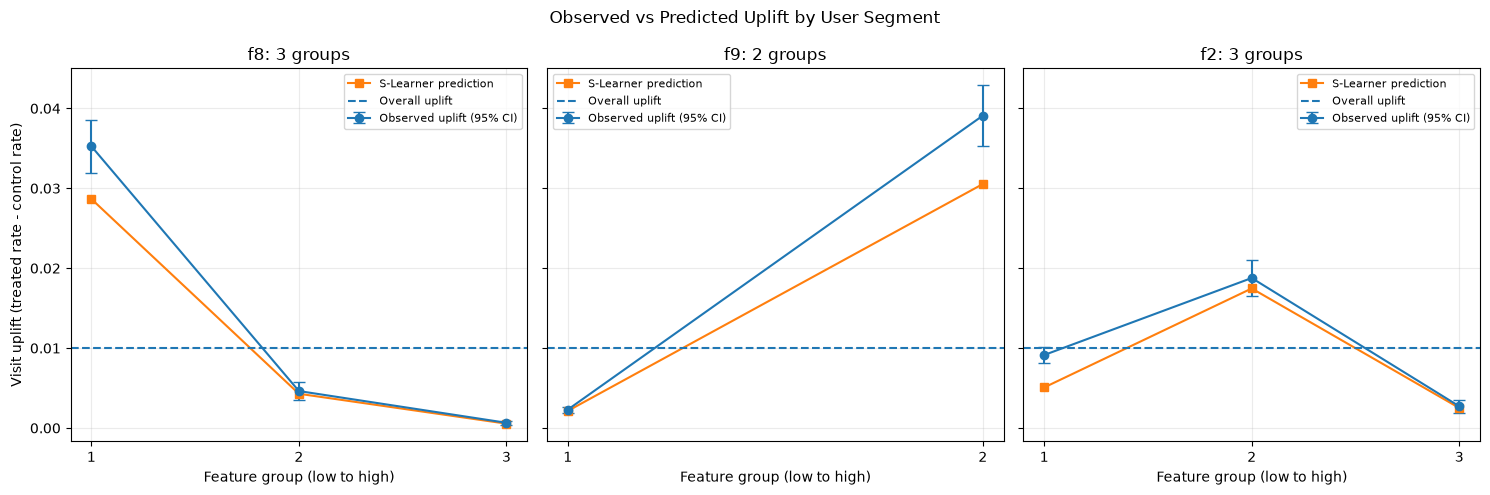

Graph saved to: /Users/kajasaikiran/Desktop/causal-uplift-git/results/segment_uplift_visit.png


In [7]:
# Step 5: Visualize segment uplift

# Calculate the overall average treatment effect
overall_treated = hold.loc[
    hold["treatment"] == 1, "visit"
].mean()

overall_control = hold.loc[
    hold["treatment"] == 0, "visit"
].mean()

overall_uplift = overall_treated - overall_control

print(f"Overall observed uplift: {overall_uplift:.6f}")

# Create one plot for each selected feature
fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), sharey=True
)

for ax, feature in zip(axes, features):

    # Get the results for this feature
    part = segment_results[
        segment_results["feature"] == feature
    ].sort_values("group")

    x = part["group"].to_numpy()
    observed = part["uplift"].to_numpy()

    # Distance from the uplift to its confidence limits
    errors = np.vstack([
        observed - part["ci_lo"].to_numpy(),
        part["ci_hi"].to_numpy() - observed
    ])

    # Actual treatment effect with 95% confidence intervals
    ax.errorbar(
        x,
        observed,
        yerr=errors,
        fmt="o-",
        capsize=4,
        label="Observed uplift (95% CI)"
    )

    # Average S-Learner prediction
    ax.plot(
        x,
        part["mean_pred_s"],
        marker="s",
        linestyle="-",
        label="S-Learner prediction"
    )

    # Overall treatment effect
    ax.axhline(
        overall_uplift,
        linestyle="--",
        label="Overall uplift"
    )

    ax.set_title(f"{feature}: {len(part)} groups")
    ax.set_xlabel("Feature group (low to high)")
    ax.set_xticks(x)
    ax.grid(alpha=0.25)

    ax.legend(fontsize=8)

axes[0].set_ylabel(
    "Visit uplift (treated rate - control rate)"
)

fig.suptitle(
    "Observed vs Predicted Uplift by User Segment"
)

plt.tight_layout()

# Save the graph
plot_path = ROOT / "results/segment_uplift_visit.png"

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Graph saved to:", plot_path)

In [13]:
# Step 6: Write the final interpretation

# Find which feature has the largest variation in observed uplift
spread = segment_results.groupby("feature")["uplift"].agg(
    lambda values: values.max() - values.min()
)

best_feature = spread.idxmax()

best_groups = segment_results[
    segment_results["feature"] == best_feature
]

# Check whether predicted and observed uplift move
# in the same direction between neighbouring groups
matches = 0
total_comparisons = 0

for feature in features:
    part = segment_results[
        segment_results["feature"] == feature
    ].sort_values("group")

    observed_change = np.diff(part["uplift"].to_numpy())
    predicted_change = np.diff(part["mean_pred_s"].to_numpy())

    matches += np.sum(
        np.sign(observed_change) == np.sign(predicted_change)
    )

    total_comparisons += len(observed_change)

# Count where the S-Learner predicts less uplift
underestimated = (
    segment_results["mean_pred_s"] < segment_results["uplift"]
).sum()

# Two conclusions, with numbers taken from the CSV table
sentence1 = (
    f"Feature {best_feature} shows the clearest change in observed "
    f"uplift, ranging from {best_groups['uplift'].min():.4f} "
    f"to {best_groups['uplift'].max():.4f} across "
    f"{len(best_groups)} groups."
)

sentence2 = (
    f"The S-Learner follows the observed direction in "
    f"{matches} out of {total_comparisons} neighbouring group "
    f"comparisons, but predicts lower uplift in "
    f"{underestimated} out of {len(segment_results)} groups."
)

from IPython.display import display, Markdown

conclusion = f"{sentence1}\n\n{sentence2}"

display(Markdown(f"### Conclusion\n\n{conclusion}"))

### Conclusion

Feature f9 shows the clearest change in observed uplift, ranging from 0.0023 to 0.0391 across 2 groups.

The S-Learner follows the observed direction in 5 out of 5 neighbouring group comparisons, but predicts lower uplift in 8 out of 8 groups.